# **Project Name**    -
   Play Store App Review Analysis: What Drives App Success






##### **Project Type**    - Exploratory Data Analysis (EDA)
##### **Contribution**    - Individual


# **Project Summary -**

This project analyses the Google Play Store to understand what separates a successful app from an unsuccessful one. Two datasets were used: Play_Store_Data, with 10,841 rows describing each app (category, rating, reviews, size, installs, type, price, content rating, last update), and User_Reviews, with 64,295 user reviews and their sentiment. Success was defined through three measures: reach (installs), satisfaction (rating and review sentiment) and engagement (number of reviews). The analysis was done in Python using pandas, NumPy, Matplotlib, Seaborn and SciPy.

The work started with data understanding: shape, data types, missing values, duplicates and a data dictionary. This revealed several problems. One row was corrupted, 1,181 apps were repeated, and Installs, Price, Size and Reviews were stored as text. "Varies with device" was hiding in Size as a latent missing value, Rating was missing for 1,463 apps, and about 42% of review rows had no text. Each problem was fixed with a documented reason: the corrupted row and duplicates were removed, text columns were converted to numbers, missing Size was filled with the median because it is skewed, and Rating was deliberately left empty to avoid inventing data. After cleaning, 9,659 unique apps and 29,692 usable reviews remained. The reviews were summarised to one row per app and joined to the Play Store data, which matched 816 apps.

The exploration followed the univariate, bivariate and multivariate order, using 20 charts. Univariate charts showed that ratings are left-skewed with a median of 4.3, that 92% of apps are free, and that 64% of reviews are positive and 21% negative. Bivariate charts compared each factor with the success measures. Education, Entertainment and Weather reach about one million median installs with few apps, while Family, Business and Medical are crowded with low median installs. Free apps have a median of 100,000 installs against only 1,000 for paid apps, and paid apps are rated slightly higher (4.4 against 4.3), a difference that a Mann-Whitney test showed is significant but small. Size has almost no link with rating, and apps with older last-update dates tend to have fewer installs. Game, the most popular category, has the lowest review sentiment, while Health and Fitness has the highest. The correlation heatmap and pair plot confirmed that reviews and installs are almost perfectly related (0.97) and that rating is only weakly related to other variables. Because installs and reviews are very skewed, medians, log scales and Spearman correlation were used instead of averages.

The recommendations to developers are to choose a less crowded category with high demand, launch a free app, update regularly, aim for a rating of at least 4.3, fix complaints from negative reviews, and encourage reviews. The main risk found is that rating alone does not make an app stand out, since most apps sit between 4.0 and 4.6, so quality must be combined with the right category and engagement.

The limitations are that findings show association, not cause, the data is a 2018 snapshot, only 816 apps have matched review data, and installs are given as ranges. Overall, the project turns raw app data into practical guidance that helps a product team decide what to build, how to price it and where to improve.

# **GitHub Link -**

GitHub Link: https://github.com/<your-username>/<repository-name>

# **Problem Statement**



Developers and product teams lack clear evidence on which app characteristics are associated with higher adoption and user satisfaction. This project explores the Play Store and User Reviews data to identify the key factors linked to app success, measured through installs, rating, review count and sentiment, and turns them into actionable recommendations.

#### **Define Your Business Objective?**



**Business Objective**

To identify which app characteristics are associated with higher **reach, user satisfaction and engagement** on the Google Play Store, so that developers and product teams can decide what to build, how to price it, and where to improve.

**Stakeholders**
- App developers and startups choosing a category or a product idea
- Product and marketing teams planning updates, pricing and growth

**How I define "success"**

| Dimension | Metric | Source |
|---|---|---|
| Reach | Installs | Play_Store_Data |
| Satisfaction | Rating, average sentiment polarity | Play_Store_Data, User_Reviews |
| Engagement | Reviews count, review-to-install ratio | Play_Store_Data |

No single metric defines success, so I analyse all three. For example, an app with 10M installs and a 3.2 rating is a different case from one with 50K installs and a 4.8 rating.

**Factors I will investigate**
Category, Type (Free/Paid), Price, Size, Content Rating, Android version, Last Updated (recency), and review sentiment.

**Key Questions**
1. Which categories have the highest installs and ratings, and which are saturated versus underserved?
2. Do free and paid apps differ in installs and ratings?
3. Do size, update recency and content rating affect success?
4. What do users praise or complain about, and which categories receive the most negative sentiment?
5. Which factors are most strongly correlated with installs and ratings?

**Expected Outcome**
A cleaned and merged dataset, an EDA with at least five types of visualisation, key insights, and actionable recommendations for developers.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 20 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





# ***Let's Begin !***

## ***1. Know Your Data***

In [ ]:
# Set the data location: Google Drive when running in Colab, otherwise the current folder
try:
    from google.colab import drive
    drive.mount('/content/drive')
    data_path = "/content/drive/MyDrive/Capstone Project 1/"
    play_file, review_file = "Play Store Data.csv", "User Reviews.csv"
except ImportError:
    data_path = ""
    play_file, review_file = "Play_Store_Data.csv", "User_Reviews.csv"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### Import Libraries

In [ ]:
# Import Libraries

# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Show charts inside the notebook
%matplotlib inline

# Hide non-critical warnings so the output stays clean
import warnings
warnings.filterwarnings("ignore")

# Set one common style for all charts
sns.set_style("whitegrid")

# Show all columns and all rows when we print a dataframe
pd.set_option("display.max_columns",None)
pd.set_option("display.max_rows",None)



### Dataset Loading

In [ ]:
# Load Dataset

# Load the Play Store apps data (one row per app)
playstore_df = pd.read_csv(data_path + play_file)

# Load the User Reviews data (many reviews per app)
reviews_df = pd.read_csv(data_path + review_file)

### Dataset First View

In [ ]:
# Dataset First Look

In [ ]:
# First 5 rows of Play Store data
playstore_df.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [ ]:
# Last 5 rows of Play Store data
playstore_df.tail()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10836,Sya9a Maroc - FR,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education,"July 25, 2017",1.48,4.1 and up
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education,"July 6, 2018",1.0,4.1 and up
10838,Parkinson Exercices FR,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical,"January 20, 2017",1.0,2.2 and up
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference,"January 19, 2015",Varies with device,Varies with device
10840,iHoroscope - 2018 Daily Horoscope & Astrology,LIFESTYLE,4.5,398307,19M,"10,000,000+",Free,0,Everyone,Lifestyle,"July 25, 2018",Varies with device,Varies with device


In [ ]:
# First 5 rows of User Reviews data
reviews_df.head()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
0,10 Best Foods for You,I like eat delicious food. That's I'm cooking ...,Positive,1.00,0.533333
1,10 Best Foods for You,This help eating healthy exercise regular basis,Positive,0.25,0.288462
2,10 Best Foods for You,NaN,NaN,NaN,NaN
3,10 Best Foods for You,Works great especially going grocery store,Positive,0.40,0.875000
4,10 Best Foods for You,Best idea us,Positive,1.00,0.300000


In [ ]:
# Last 5 rows of User Reviews data
reviews_df.tail()

,App,Translated_Review,Sentiment,Sentiment_Polarity,Sentiment_Subjectivity
64290,Houzz Interior Design Ideas,NaN,NaN,NaN,NaN
64291,Houzz Interior Design Ideas,NaN,NaN,NaN,NaN
64292,Houzz Interior Design Ideas,NaN,NaN,NaN,NaN
64293,Houzz Interior Design Ideas,NaN,NaN,NaN,NaN
64294,Houzz Interior Design Ideas,NaN,NaN,NaN,NaN


### Dataset Rows & Columns count

In [ ]:
# Dataset Rows & Columns count

# Play Store data
print("Play Store data")
print("Number of rows   :", playstore_df.shape[0])
print("Number of columns:", playstore_df.shape[1])

print("-------------------------------------------------")

# User Reviews data
print("User Reviews data")
print("Number of rows   :", reviews_df.shape[0])
print("Number of columns:", reviews_df.shape[1])

Play Store data
Number of rows   : 10841
Number of columns: 13
-------------------------------------------------
User Reviews data
Number of rows   : 64295
Number of columns: 5


### Dataset Information

In [ ]:
# Dataset Info

In [ ]:
# Play Store data
print("Play Store data")
playstore_df.info()

Play Store data
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [ ]:
# User Reviews data
print("User Reviews data")
reviews_df.info()

User Reviews data
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64295 entries, 0 to 64294
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   App                     64295 non-null  object 
 1   Translated_Review       37427 non-null  object 
 2   Sentiment               37432 non-null  object 
 3   Sentiment_Polarity      37432 non-null  float64
 4   Sentiment_Subjectivity  37432 non-null  float64
dtypes: float64(2), object(3)
memory usage: 2.5+ MB


#### Duplicate Values

In [ ]:
# Dataset Duplicate Value Count

# Play Store data: rows that are exact copies of an earlier row
print("Play Store duplicate rows   :", playstore_df.duplicated().sum())

# User Reviews data
print("User Reviews duplicate rows :", reviews_df.duplicated().sum())

Play Store duplicate rows   : 483
User Reviews duplicate rows : 33616


#### Missing Values/Null Values

In [ ]:
# Missing Values/Null Values Count

# Play Store data: count of nulls in each column
print("Play Store data")
print(playstore_df.isnull().sum())


# User Reviews data
print("\nUser Reviews data")
print(reviews_df.isnull().sum())

Play Store data
App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

User Reviews data
App                           0
Translated_Review         26868
Sentiment                 26863
Sentiment_Polarity        26863
Sentiment_Subjectivity    26863
dtype: int64


In [ ]:
# Visualizing the missing values

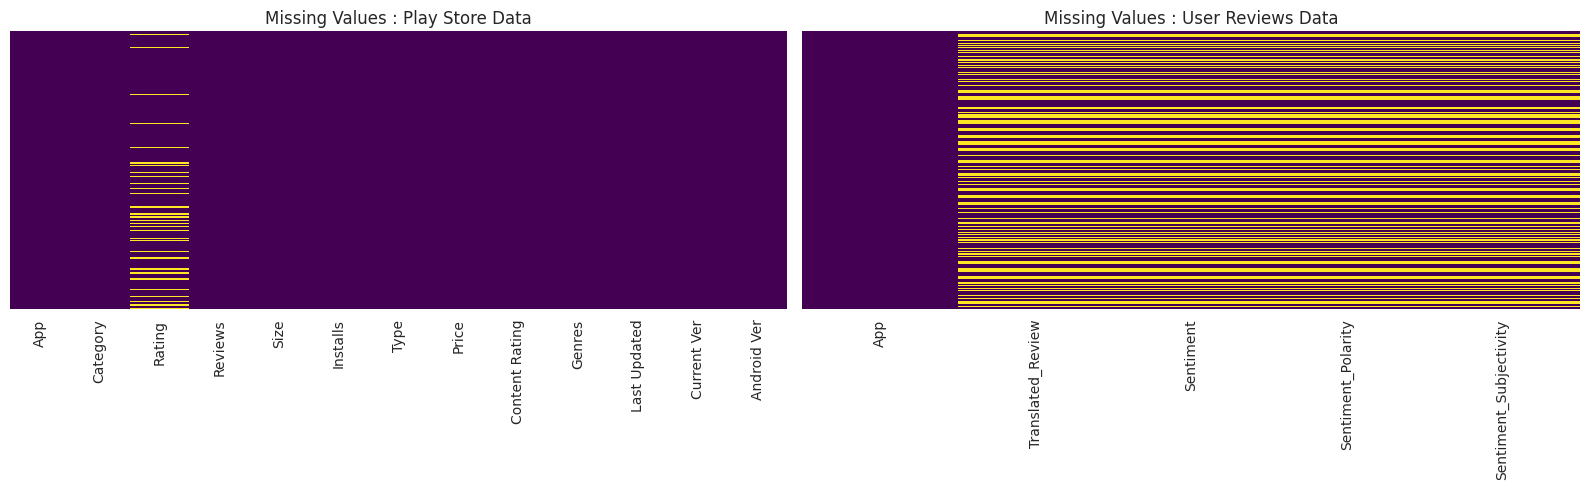

In [ ]:
# Create two charts side by side : one for each dataset
fig, axes = plt.subplots(1,2, figsize=(16, 5))

# Play Store data: heatmap, each white line is a missing value
sns.heatmap(playstore_df.isnull(), cbar=False, yticklabels=False, cmap='viridis', ax=axes[0])
axes[0].set_title("Missing Values : Play Store Data")

# User Reviews data
sns.heatmap(reviews_df.isnull(), cbar=False, yticklabels=False, cmap='viridis', ax=axes[1])
axes[1].set_title("Missing Values : User Reviews Data")

plt.tight_layout()
plt.show()

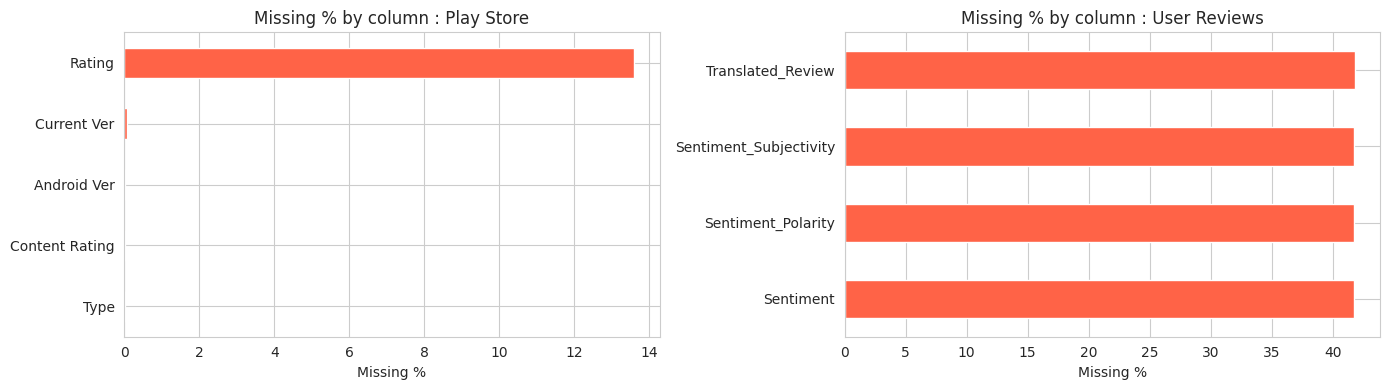

In [ ]:
# Missing value percentage per column (only columns that have missing values)

fig, axes = plt.subplots(1,2, figsize=(14, 4))

for ax, data, name in [(axes[0], playstore_df, "Play Store"), (axes[1], reviews_df, "User Reviews")]:
  missing_pct = (data.isnull().mean() * 100)        # percentage of nulls as per column
  missing_pct = missing_pct[missing_pct > 0].sort_values()
  missing_pct.plot(kind="barh", ax=ax, color="tomato")
  ax.set_title(f"Missing % by column : {name}")
  ax.set_xlabel("Missing %")

plt.tight_layout()
plt.show()

### What did you know about your dataset?



**Play Store Data**
- It has 10,841 rows and 13 columns. Each row is one app, with details like Category, Rating, Reviews, Size, Installs, Type, Price, Content Rating, Genres, Last Updated, Current Ver and Android Ver.
- Only `Rating` is numeric. `Reviews`, `Size`, `Installs` and `Price` are stored as text (for example "10,000+", "19M", "$4.99"), so they need to be converted to numbers.
- `Last Updated` is stored as text and needs to be converted to a date.
- There are 483 duplicate rows.
- `Rating` has 1,474 missing values (about 13.6%). `Type`, `Content Rating`, `Current Ver` and `Android Ver` have only a few missing values.
- One row looks corrupted (the values have shifted, for example Category = 1.9 and Installs = Free), so it needs to be removed.

**User Reviews Data**
- It has 64,295 rows and 5 columns: App, Translated_Review, Sentiment, Sentiment_Polarity and Sentiment_Subjectivity. Each row is one review.
- There are 33,616 duplicate rows.
- About 26,863 rows (around 42%) have no sentiment values, and most of them also have no review text, so they carry no information.

**How the two datasets connect**
- Both share the `App` column. One app can have many reviews, so the reviews will be summarised to one row per app before merging with the Play Store data.

**Next steps**
- Remove duplicates, fix the corrupted row, handle missing values, convert data types, and then merge the two datasets.

In [ ]:
print(playstore_df["Category"].unique())   # '1.9'

['ART_AND_DESIGN' 'AUTO_AND_VEHICLES' 'BEAUTY' 'BOOKS_AND_REFERENCE'
 'BUSINESS' 'COMICS' 'COMMUNICATION' 'DATING' 'EDUCATION' 'ENTERTAINMENT'
 'EVENTS' 'FINANCE' 'FOOD_AND_DRINK' 'HEALTH_AND_FITNESS' 'HOUSE_AND_HOME'
 'LIBRARIES_AND_DEMO' 'LIFESTYLE' 'GAME' 'FAMILY' 'MEDICAL' 'SOCIAL'
 'SHOPPING' 'PHOTOGRAPHY' 'SPORTS' 'TRAVEL_AND_LOCAL' 'TOOLS'
 'PERSONALIZATION' 'PRODUCTIVITY' 'PARENTING' 'WEATHER' 'VIDEO_PLAYERS'
 'NEWS_AND_MAGAZINES' 'MAPS_AND_NAVIGATION' '1.9']


## ***2. Understanding Your Variables***

In [ ]:
# Dataset Columns

# Play Store data: column names
print("Play Store columns:")
print(list(playstore_df.columns))

# User Reviews data: column names
print("\nUser Reviews columns:")
print(list(reviews_df.columns))

Play Store columns:
['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']

User Reviews columns:
['App', 'Translated_Review', 'Sentiment', 'Sentiment_Polarity', 'Sentiment_Subjectivity']


In [ ]:
# Dataset Describe

# Play Store data: summary of numeric columns
print("Play Store data")
display(playstore_df.describe())

# User Reviews data: summary of numeric columns
print("\nUser Reviews data")
display(reviews_df.describe())

Play Store data


,Rating
count,9367.000000
mean,4.193338
std,0.537431
min,1.000000
25%,4.000000
50%,4.300000
75%,4.500000
max,19.000000



User Reviews data


,Sentiment_Polarity,Sentiment_Subjectivity
count,37432.000000,37432.000000
mean,0.182146,0.492704
std,0.351301,0.259949
min,-1.000000,0.000000
25%,0.000000,0.357143
50%,0.150000,0.514286
75%,0.400000,0.650000
max,1.000000,1.000000


### Variables Description



**Play Store Data** (one row per app)

| Column | Description | Current Type | Planned Action |
|---|---|---|---|
| App | Name of the app | Text | Used as the join key |
| Category | Category the app belongs to (e.g. GAME, FAMILY, TOOLS) | Text | Keep as categorical |
| Rating | Average user rating (1 to 5) | Float | Handle missing values, remove invalid value |
| Reviews | Number of user reviews | Text | Convert to integer |
| Size | Size of the app (e.g. "19M", "Varies with device") | Text | Convert to a number in MB |
| Installs | Number of installs (e.g. "10,000+") | Text | Remove "+" and ",", convert to integer |
| Type | Free or Paid | Text | Keep as categorical |
| Price | Price of the app (e.g. "$4.99") | Text | Remove "$", convert to float |
| Content Rating | Target age group (Everyone, Teen, Mature 17+, etc.) | Text | Keep as categorical |
| Genres | More specific genre(s) of the app | Text | Keep as categorical |
| Last Updated | Date of the last update | Text | Convert to datetime |
| Current Ver | Current version of the app | Text | Keep for reference, low importance |
| Android Ver | Minimum Android version required | Text | Keep as categorical |

**User Reviews Data** (many rows per app)

| Column | Description | Current Type | Planned Action |
|---|---|---|---|
| App | Name of the app | Text | Join key |
| Translated_Review | Text of the user review | Text | Drop rows with no review text |
| Sentiment | Review sentiment: Positive, Negative or Neutral | Text | Keep as categorical |
| Sentiment_Polarity | Sentiment score from -1 (negative) to +1 (positive) | Float | Average per app |
| Sentiment_Subjectivity | Score from 0 (factual) to 1 (opinion) | Float | Average per app |

### Check Unique Values for each variable.

In [ ]:
# Check Unique Values for each variable.

# Play Store data: number of unique values in each column
print("Play Store data")
print(playstore_df.nunique())

# User Reviews data
print("\nUser Reviews data")
print(reviews_df.nunique())

Play Store data
App               9660
Category            34
Rating              40
Reviews           6002
Size               462
Installs            22
Type                 3
Price               93
Content Rating       6
Genres             120
Last Updated      1378
Current Ver       2832
Android Ver         33
dtype: int64

User Reviews data
App                        1074
Translated_Review         27994
Sentiment                     3
Sentiment_Polarity         5410
Sentiment_Subjectivity     4474
dtype: int64


In [ ]:
# # Actual values of the small categorical columns
# for col in ["Type", "Content Rating"]:
#     print(col, "->", playstore_df[col].unique())

Type -> ['Free' 'Paid' nan '0']
Content Rating -> ['Everyone' 'Teen' 'Everyone 10+' 'Mature 17+' 'Adults only 18+' 'Unrated'
 nan]


## 3. ***Data Wrangling***

### Data Wrangling Code

In [ ]:
# Write your code to make your dataset analysis ready.

# ---------- PLAY STORE DATA ----------

# Work on a copy so the raw data stays safe
df = playstore_df.copy()

# 1. Remove the corrupted row (Category = 1.9, values are shifted)
# Category = "1.9" is a corrupted row (values are shifted)
print("Before:", df.shape)
df = df[df["Category"] != "1.9"]
print("After :", df.shape)

print("*************************************************************************************")

# 2. Convert Reviews to number (needed before removing duplicates)
df["Reviews"] = pd.to_numeric(df["Reviews"], errors="coerce")
print(df["Reviews"].dtype)

print("*************************************************************************************")

# # 3. Remove duplicate apps: keep the row with the highest review count (latest data)
print("Before:", df.shape)
df = df.sort_values("Reviews", ascending=False)
df = df.drop_duplicates(subset="App", keep="first").reset_index(drop=True)
print("After :", df.shape)
print("Duplicate apps left:", df["App"].duplicated().sum())

print("*************************************************************************************")

# 4. Installs: "10,000+" -> 10000
# "10,000+" -> 10000
df["Installs"] = df["Installs"].str.replace("[+,]", "", regex=True).astype(int)
print(df["Installs"].dtype)

print("*************************************************************************************")

# 5. Price: "$4.99" -> 4.99
df["Price"] = df["Price"].str.replace("$","",regex=False).astype(float)
print(df["Price"].dtype)
print("Max price:", df["Price"].max())

print("*************************************************************************************")

# 6. Size: convert everything to MB
# Convert Size to MB
def size_to_mb(size):
    """Convert Size text like '19M' or '201k' to a number in MB."""
    if size == "Varies with device":
        return np.nan                      # no real value, treat as missing
    if size.endswith("M"):
        return float(size[:-1])
    if size.endswith("k"):
        return float(size[:-1]) / 1024     # 1 MB = 1024 KB
    return np.nan

df["Size"] = df["Size"].apply(size_to_mb)
print(df["Size"].dtype)
print("Missing Size:", df["Size"].isnull().sum())

print("*************************************************************************************")

# 7. Last Updated: text -> datetime
# Text -> datetime
df["Last Updated"] = pd.to_datetime(df["Last Updated"], errors="coerce")
print(df["Last Updated"].dtype)
print("Oldest:", df["Last Updated"].min(), "| Latest:", df["Last Updated"].max())

print("*************************************************************************************")

# 8. Missing values
# Type: the one missing app has Price 0, so it is Free
df["Type"] = df["Type"].fillna("Free")

# Size: median, because a few very large apps would pull the mean up
df["Size"] = df["Size"].fillna(df["Size"].median())

# Versions: small number missing, mark as Unknown
df["Current Ver"] = df["Current Ver"].fillna("Unknown")
df["Android Ver"] = df["Android Ver"].fillna("Unknown")

# Rating is NOT filled: a made-up rating would distort the analysis
print(df.isnull().sum())

# ---------- USER REVIEWS DATA ----------

# 1. Remove duplicate reviews
# Remove duplicate reviews
reviews = reviews_df.copy()
print("Before:", reviews.shape)
reviews = reviews.drop_duplicates()

# Remove rows with no review text or sentiment (they carry no information)
reviews = reviews.dropna(subset=["Translated_Review", "Sentiment"]).reset_index(drop=True)
print("After :", reviews.shape)
print(reviews.isnull().sum())

print("*************************************************************************************")

# 2. Remove rows with no review text or sentiment (no information)
# Final check of both cleaned datasets
print("Play Store:", df.shape)
df.info()
print("\nUser Reviews:", reviews.shape)

# ---------- Check the result ----------

Before: (10841, 13)
After : (10840, 13)
*************************************************************************************
int64
*************************************************************************************
Before: (10840, 13)
After : (9659, 13)
Duplicate apps left: 0
*************************************************************************************
int64
*************************************************************************************
float64
Max price: 400.0
*************************************************************************************
float64
Missing Size: 1228
*************************************************************************************
datetime64[ns]
Oldest: 2010-05-21 00:00:00 | Latest: 2018-08-08 00:00:00
*************************************************************************************
App                  0
Category             0
Rating            1463
Reviews              0
Size                 0
Installs             0
Type                 

### Reusable Cleaning Functions
The same cleaning steps packaged as functions, so they can be reused on new data. The check below confirms the result matches the step-by-step version.

In [ ]:
# Reusable cleaning functions (same logic as the steps above)

def clean_playstore(raw):
    """Clean the Play Store data: remove bad rows, fix types, handle missing values."""
    d = raw.copy()
    d = d[d["Category"] != "1.9"]                                           # corrupted row
    d["Reviews"] = pd.to_numeric(d["Reviews"], errors="coerce")             # text -> number
    d = d.sort_values("Reviews", ascending=False).drop_duplicates(subset="App", keep="first").reset_index(drop=True)
    d["Installs"] = d["Installs"].str.replace("[+,]", "", regex=True).astype(int)
    d["Price"] = d["Price"].str.replace("$", "", regex=False).astype(float)
    d["Size"] = d["Size"].apply(size_to_mb)                                 # uses size_to_mb defined above
    d["Last Updated"] = pd.to_datetime(d["Last Updated"], errors="coerce")
    d["Type"] = d["Type"].fillna("Free")
    d["Size"] = d["Size"].fillna(d["Size"].median())
    d["Current Ver"] = d["Current Ver"].fillna("Unknown")
    d["Android Ver"] = d["Android Ver"].fillna("Unknown")
    return d

def clean_reviews(raw):
    """Clean the reviews data: remove duplicates and rows without text or sentiment."""
    d = raw.drop_duplicates()
    return d.dropna(subset=["Translated_Review", "Sentiment"]).reset_index(drop=True)

# Check: the functions give the same result as the step-by-step cleaning
print("Play Store matches step-by-step result:", clean_playstore(playstore_df).equals(df))
print("Reviews matches step-by-step result   :", clean_reviews(reviews_df).equals(reviews))

Play Store matches step-by-step result: True
Reviews matches step-by-step result   : True


### What all manipulations have you done and insights you found?

**Manipulations done**

*Play Store data*
1. Made a copy of the raw data so the original stays safe.
2. Removed 1 corrupted row (Category = "1.9"), where the values had shifted.
3. Converted `Reviews` from text to number.
4. Removed 1,181 duplicate rows, keeping the row with the highest review count for each app. The data is now one row per app (9,659 apps).
5. Converted `Installs` ("10,000+") and `Price` ("$4.99") from text to numbers.
6. Converted `Size` to MB. "Varies with device" became missing, and sizes in KB were divided by 1024.
7. Converted `Last Updated` from text to datetime.
8. Handled missing values: `Type` filled with "Free", `Size` filled with the median (12 MB), `Current Ver` and `Android Ver` filled with "Unknown". `Rating` was left missing on purpose.

*User Reviews data*
1. Removed duplicate reviews.
2. Removed rows with no review text or sentiment.
3. Rows reduced from 64,295 to 29,692, covering 865 apps.

**Insights found**
- **The Play Store data had a real quality problem.** About 11% of rows (1,181 of 10,840) were repeated apps, which would have counted the same app twice in every chart.
- **Rating is missing for 1,463 apps (about 15%).** I did not fill these, so rating analysis uses only the 8,196 apps that have a rating.
- **Ratings are high overall.** The median rating is 4.3 and the mean is 4.17, so most apps are rated above 4.
- **Reviews are heavily skewed.** The median is about 969 reviews, but the mean is about 216,000. A few very popular apps pull the mean up, so I will use the median for comparisons.
- **Size was a hidden missing value.** About 1,228 apps (around 13%) have "Varies with device", which `isnull()` could not find.
- **Price has an extreme value.** The maximum price is $400, so price will be treated carefully as an outlier.
- **Data covers 2010 to 2018.** Most apps were updated in 2017 and 2018, so "days since update" will be measured from the latest date in the data (August 2018).
- **Reviews are mostly positive.** Of the 29,692 usable reviews, about 64% are positive, 21% negative and 15% neutral.
- **Only 865 apps have reviews**, out of 9,659. So sentiment insights will cover a small part of the apps, and the merge will leave many apps without sentiment.

### Merge Play Store and User Reviews data

Aggregate the reviews to one row per app, drop duplicates, then left join onto the Play Store data.

In [ ]:
# Merge: add review sentiment to the Play Store data

# Step 1: summarise reviews to one row per app
app_sentiment = reviews.groupby("App").agg(
    review_count=("Sentiment", "count"),                                   # usable reviews per app
    avg_polarity=("Sentiment_Polarity", "mean"),                           # average sentiment score
    pct_positive=("Sentiment", lambda s: (s == "Positive").mean() * 100),  # % positive reviews
    pct_negative=("Sentiment", lambda s: (s == "Negative").mean() * 100)   # % negative reviews
).reset_index()

# Step 2: drop duplicates on the external data (safety check)
app_sentiment = app_sentiment.drop_duplicates(subset="App")

# Step 3: left join, so every Play Store app is kept
merged_df = df.merge(app_sentiment, on="App", how="left")

print("Merged shape:", merged_df.shape)
print("Apps with sentiment data:", merged_df["avg_polarity"].notna().sum())

Merged shape: (9659, 17)
Apps with sentiment data: 816


### Hypotheses / Assumptions

| # | Hypothesis | Result |
|---|---|---|
| H1 | Free apps get more installs than paid apps | **Supported:** median 100,000 vs 1,000 |
| H2 | Paid apps get better ratings | **Partly supported:** 4.4 vs 4.3, statistically significant but small |
| H3 | Larger apps get lower ratings | **Rejected:** correlation about 0.06 |
| H4 | Recently updated apps get more installs | **Supported:** correlation of -0.33 between days since update and installs (Chart 19) |
| H5 | Reviews grow with installs | **Supported:** correlation 0.97 |
| H6 | Some categories are more crowded and less rewarding | **Supported:** Family, Business and Medical vs Education and Weather |
| H7 | Review sentiment differs by category | **Supported:** Game is lowest (0.06), Health & Fitness highest (0.31) |

**Assumptions:** Installs are treated as a range (for example 10,000+). Medians are used because the data is skewed. The data is a 2018 snapshot. Findings show association, not cause.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

### Univariate Analysis (Charts 1 to 7)
One variable at a time: shape, skew, spread and outliers.

#### Chart - 1 - Rating Distribution

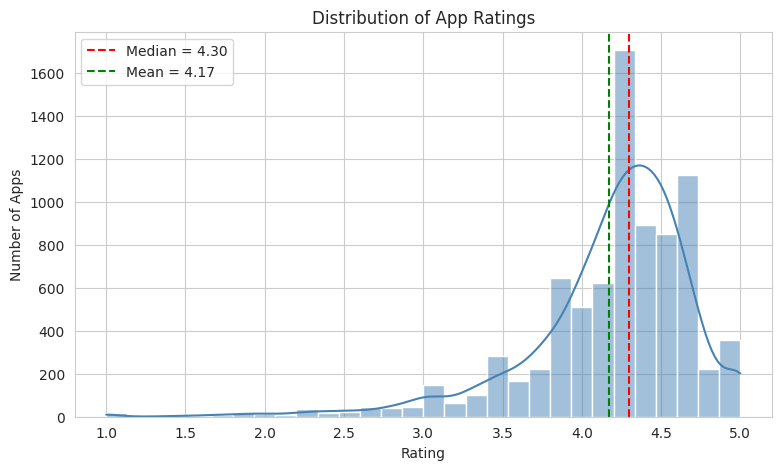

In [ ]:
# Chart - 1 visualization code

# Use only apps that have a rating (missing ratings were left empty on purpose)
ratings = df["Rating"].dropna()

plt.figure(figsize=(9, 5))

# Histogram with a smooth KDE line to show the shape
sns.histplot(ratings, bins=30, kde=True, color="steelblue")

# Mark the median and mean to compare them
plt.axvline(ratings.median(), color="red", linestyle="--", label=f"Median = {ratings.median():.2f}")
plt.axvline(ratings.mean(), color="green", linestyle="--", label=f"Mean = {ratings.mean():.2f}")

plt.title("Distribution of App Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Apps")
plt.legend()
plt.show()

##### 1. Why did you pick the specific chart?

A histogram with KDE shows the shape of one numerical variable, so we can see where most ratings sit and whether they are skewed.

##### 2. What is/are the insight(s) found from the chart?

Ratings are left-skewed, with a median of 4.3 and a mean of 4.17. About 77% of apps are rated 4.0 or above, and only about 3% are below 3.0.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: a rating of 4.3 is the market benchmark, so developers should aim for at least 4.0 to stay level with most competitors.
Negative: since most apps sit between 4.0 and 4.6, rating alone does not make an app stand out, so developers need other strengths too.

#### Chart - 2 - Free vs Paid Apps

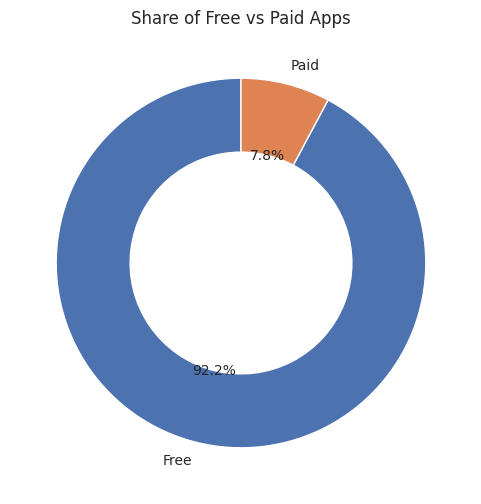

In [ ]:
# Chart - 2 visualization code

# Count of free and paid apps
type_counts = df["Type"].value_counts()

plt.figure(figsize=(6, 6))

# Donut chart: pie chart with a white circle in the middle
plt.pie(type_counts, labels=type_counts.index, autopct="%1.1f%%",
        startangle=90, colors=["#4C72B0", "#DD8452"],
        wedgeprops={"width": 0.4})

plt.title("Share of Free vs Paid Apps")
plt.show()

##### 1. Why did you pick the specific chart?

Type has only two categories, so a donut chart shows each one's share of the whole clearly.

##### 2. What is/are the insight(s) found from the chart?

About 92% of apps are free (8,905) and only about 8% are paid (754).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: paid apps are only 8% of the market, so a good paid app faces less direct competition than a free one.
Negative: with 92% of apps free, users expect apps to cost nothing, so a paid app may struggle to get installs. Developers who want revenue should consider a free app with ads or in-app purchases.

#### Chart - 3 - Outliers in Numeric Columns

          outliers  outlier_%    median        mean
Rating         491        6.0       4.3        4.17
Reviews       1659       17.2     969.0   216804.11
Installs      1981       20.5  100000.0  7798170.25
Size           762        7.9      12.0       19.33
Price          754        7.8       0.0        1.10


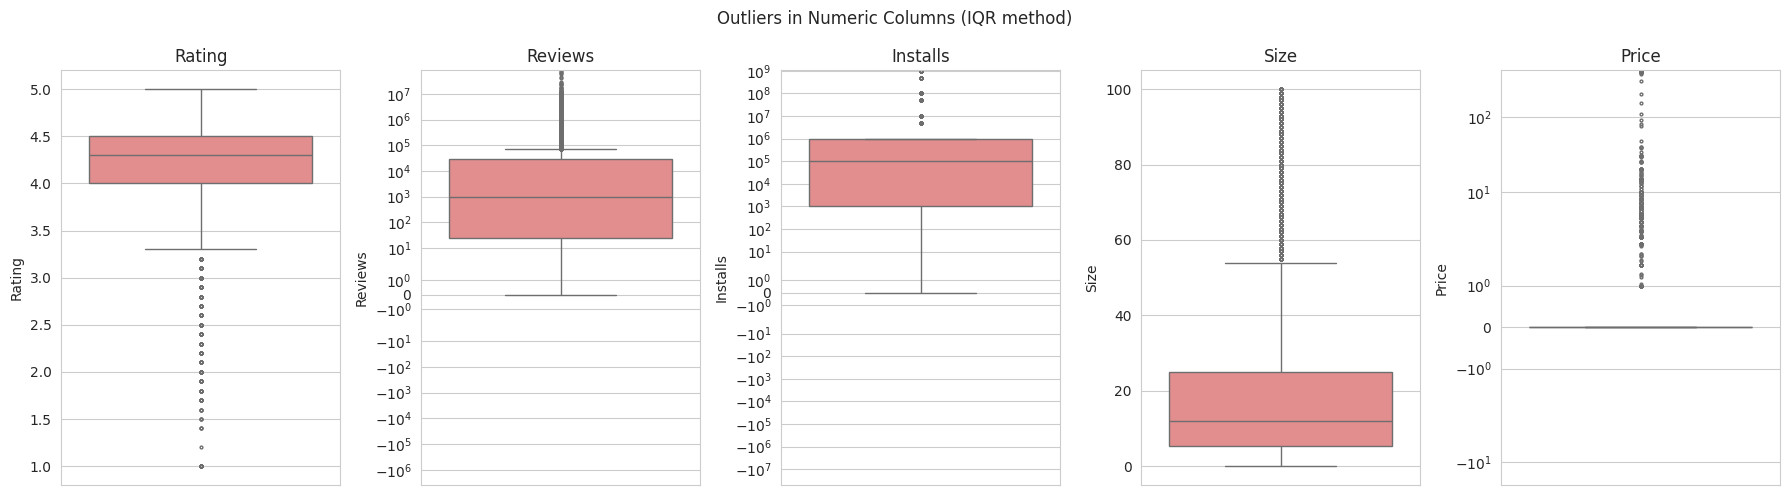

In [ ]:
# Chart - 3 visualization code

# Outliers are flagged with the IQR method (1.5 x IQR rule); real values are kept, not dropped
def flag_outliers_iqr(data, col):
    """Return True for values outside 1.5 x IQR from the quartiles."""
    q1, q3 = data[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    return (data[col] < q1 - 1.5 * iqr) | (data[col] > q3 + 1.5 * iqr)

cols = ["Rating", "Reviews", "Installs", "Size", "Price"]
for col in cols:
    df["outlier_" + col] = flag_outliers_iqr(df, col)

# Summary table: how many outliers, and how far mean is from median
outlier_summary = pd.DataFrame({
    "outliers": [df["outlier_" + c].sum() for c in cols],
    "outlier_%": [round(df["outlier_" + c].sum() / df[c].notna().sum() * 100, 1) for c in cols],
    "median": [df[c].median() for c in cols],
    "mean": [round(df[c].mean(), 2) for c in cols]}, index=cols)
print(outlier_summary)

# One box plot per column; symlog scale for the very skewed columns
fig, axes = plt.subplots(1, 5, figsize=(18, 5))
for ax, col in zip(axes, cols):
    sns.boxplot(y=df[col], ax=ax, color="lightcoral", flierprops={"markersize": 2})
    ax.set_title(col)
    if col in ["Reviews", "Installs", "Price"]:
        ax.set_yscale("symlog")
plt.suptitle("Outliers in Numeric Columns (IQR method)")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

A box plot shows outliers directly as dots beyond the whiskers, so one row of five plots checks all numeric columns at once.

##### 2. What is/are the insight(s) found from the chart?

Installs (20.5%) and Reviews (17.2%) have the most outliers, and their means are far above the medians (installs 7.8 million vs 100,000, reviews about 217,000 vs 969), so a few giant apps pull the averages up. Rating outliers (6.0%) are all low ratings below 3.25. Price shows 754 outliers only because 92% of apps are free, so any paid app falls outside the box.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: these outliers are real, successful apps (like Facebook), so keeping them and using medians shows the true typical app, and developers can use the median as a realistic target. Negative: a developer who compares against the mean (7.8 million installs) would set an unrealistic goal and misjudge the market. The low-rating outliers are also a warning that a small group of apps fail on quality.

**Note:** The impossible Rating of 19 was already removed with the corrupted row. The other flagged values are real, so they are kept and flagged, and medians and log scales are used instead.

#### Chart - 4 - Top 10 Categories by Number of Apps

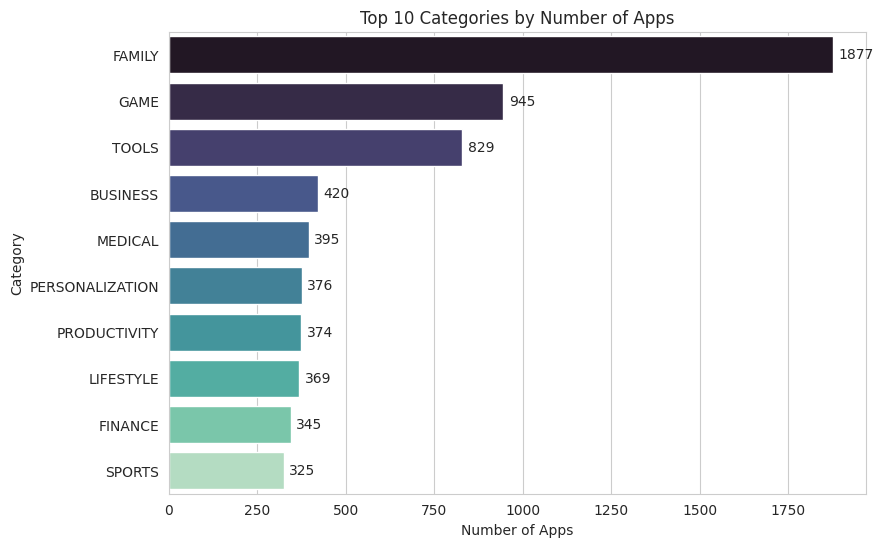

In [ ]:
# Chart - 4 visualization code

# Top 10 categories by number of apps
top10 = df["Category"].value_counts().head(10)

plt.figure(figsize=(9, 6))
ax = sns.barplot(x=top10.values, y=top10.index, palette="mako")

# Write the count at the end of each bar
for i, value in enumerate(top10.values):
    ax.text(value + 15, i, value, va="center")

plt.title("Top 10 Categories by Number of Apps")
plt.xlabel("Number of Apps")
plt.ylabel("Category")
plt.show()

##### 1. Why did you pick the specific chart?

Category is a categorical variable with 33 values, so showing only the top 10 in a horizontal bar chart keeps it readable and makes the biggest categories easy to compare.

##### 2. What is/are the insight(s) found from the chart?

FAMILY leads with 1,876 apps (about 19%), followed by GAME (945) and TOOLS (829). The top 3 categories hold about 38% of all apps, and the top 10 hold about 65%.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: a high app count shows where user demand and developer activity are strong, so these categories are proven markets. Smaller categories like Beauty (53 apps) and Parenting (60 apps) have far fewer competitors, which gives new developers a chance to stand out.
Negative: the top categories are crowded, because FAMILY alone has about 1,900 apps competing for attention, so a new app there is harder to discover. A high app count does not mean high installs, so we need the installs charts before choosing a category.

#### Chart - 5 - Number of Apps by Install Group

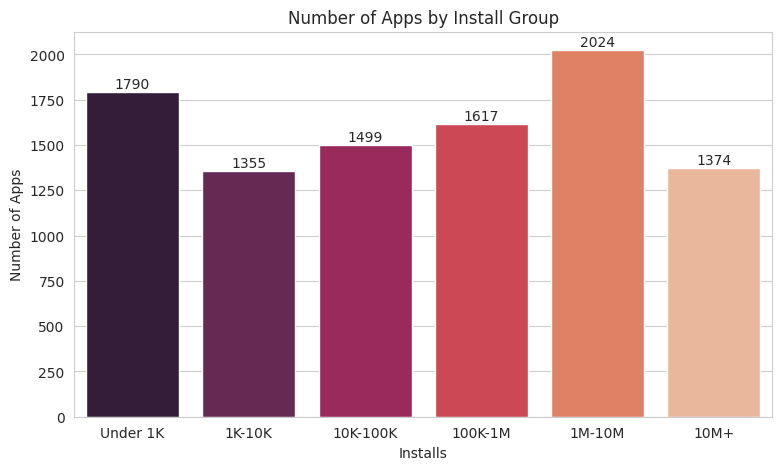

In [ ]:
# Chart - 5 visualization code

# Create install groups (buckets) from the Installs number
bins = [-1, 999, 9999, 99999, 999999, 9999999, float("inf")]
labels = ["Under 1K", "1K-10K", "10K-100K", "100K-1M", "1M-10M", "10M+"]
df["Install_Bucket"] = pd.cut(df["Installs"], bins=bins, labels=labels)

# Count apps in each bucket, in the correct order
bucket_counts = df["Install_Bucket"].value_counts().reindex(labels)

plt.figure(figsize=(9, 5))
ax = sns.barplot(x=bucket_counts.index, y=bucket_counts.values, palette="rocket")

# Write the count on top of each bar
for i, value in enumerate(bucket_counts.values):
    ax.text(i, value + 20, value, ha="center")

plt.title("Number of Apps by Install Group")
plt.xlabel("Installs")
plt.ylabel("Number of Apps")
plt.show()

##### 1. Why did you pick the specific chart?

Raw installs range from 0 to 1 billion, so a histogram would be unreadable. Grouping installs into buckets and using a bar chart makes the spread easy to see.

##### 2. What is/are the insight(s) found from the chart?

Apps are spread across all install groups. The largest group is 1M-10M (2,024 apps, about 21%), and the 10M+ group has 1,374 apps (about 14%). About 18% of apps (1,790) have under 1,000 installs. The median is 100,000 installs, but the mean is about 7.8 million, so a few giant apps pull the mean up.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: about 35% of apps reach over 1 million installs, so large reach is achievable, and developers can set 100K-1M installs as a realistic first target.
Negative: almost 1 in 5 apps (18%) stays under 1,000 installs, which means many apps fail to get discovered at all. Also, the mean is far above the median, so quoting average installs would overstate what a typical app achieves, and the median should be used for planning.

#### Chart - 6 - Distribution of App Size

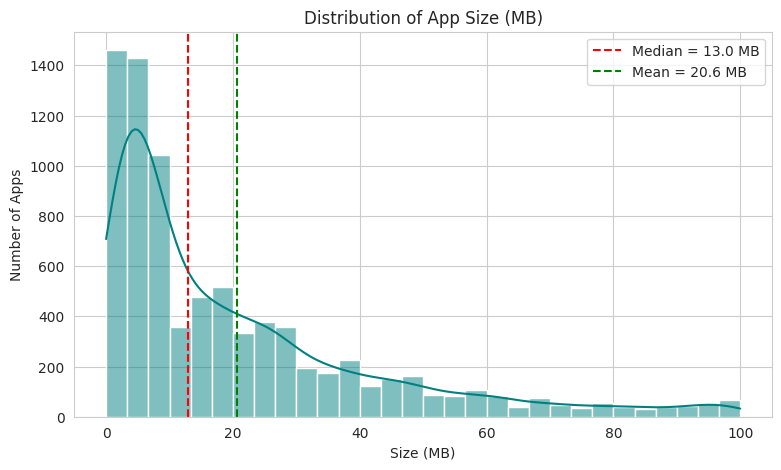

In [ ]:
# Chart - 6 visualization code

# Size has a tall spike at 12 MB because we filled missing sizes with the median.
# Remove that filled value so the chart shows only real app sizes.
sizes = df.loc[df["Size"] != df["Size"].median(), "Size"]

plt.figure(figsize=(9, 5))

# Histogram with KDE to show the shape
sns.histplot(sizes, bins=30, kde=True, color="teal")

# Mark the median and mean
plt.axvline(sizes.median(), color="red", linestyle="--", label=f"Median = {sizes.median():.1f} MB")
plt.axvline(sizes.mean(), color="green", linestyle="--", label=f"Mean = {sizes.mean():.1f} MB")

plt.title("Distribution of App Size (MB)")
plt.xlabel("Size (MB)")
plt.ylabel("Number of Apps")
plt.legend()
plt.show()

##### 1. Why did you pick the specific chart?

Size is a numerical variable, so a histogram with KDE shows where most apps sit and whether the data is skewed. The median and mean lines show the skew directly.

##### 2. What is/are the insight(s) found from the chart?

Size is right-skewed. The median is about 13 MB and the mean is about 21 MB, because a few large apps pull the mean up. About 64% of apps are under 20 MB, about 89% are under 50 MB, and only about 11% are above 50 MB. The size tops out at 100 MB.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: most apps are under 20 MB, so developers can use about 13 MB as a size benchmark. A smaller app downloads faster and works on low-storage phones, which is useful for a large user base.
Negative: about 1 in 10 apps is above 50 MB, and these are mostly heavy apps like games. Users with limited storage or slow internet may skip them, so a large app risks losing installs unless it offers something special. Whether size really hurts installs needs the next charts, so we should not conclude it from this one.

#### Chart - 7 - Sentiment of User Reviews

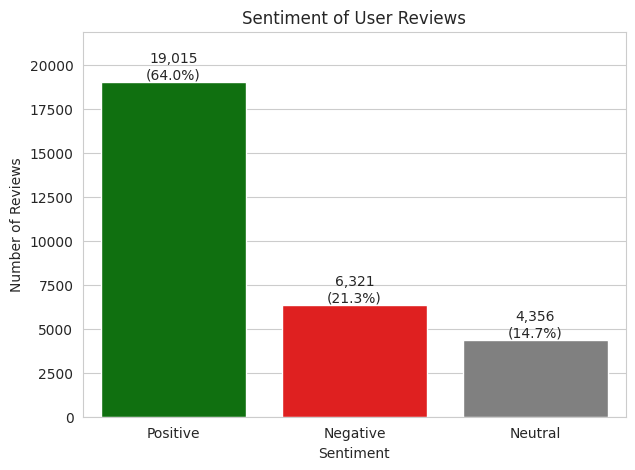

In [ ]:
# Chart - 7 visualization code

# Count of reviews in each sentiment (Positive, Negative, Neutral)
sentiment_counts = reviews["Sentiment"].value_counts()

plt.figure(figsize=(7, 5))
ax = sns.barplot(x=sentiment_counts.index, y=sentiment_counts.values,
                 palette=["green", "red", "gray"])

# Write count and percentage on top of each bar
total = sentiment_counts.sum()
for i, value in enumerate(sentiment_counts.values):
    ax.text(i, value + 200, f"{value:,}\n({value / total:.1%})", ha="center")

plt.title("Sentiment of User Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.ylim(0, sentiment_counts.max() * 1.15)   # extra space above bars for labels
plt.show()

##### 1. Why did you pick the specific chart?

Sentiment is a categorical variable with three values, so a bar chart compares the number of reviews in each group clearly, and the labels add the percentages.

##### 2. What is/are the insight(s) found from the chart?

Out of 29,692 reviews, 64% are positive (19,015), 21% are negative (6,321) and 15% are neutral (4,356). So about 3 in 10 reviews are not positive.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: with about 64% of reviews positive, users are generally satisfied, so developers can expect appreciation when the app works well.
Negative: 21% of reviews are negative, which is about 1 review in 5, and negative reviews are what other users read before installing. Developers should read these complaints and fix them early. Also, these reviews cover only 865 of the 9,659 apps, so this is a partial view of the market.

### Bivariate Analysis (Charts 8 to 18)
One factor against a success measure. Charts 8 to 12: numerical vs categorical. Charts 13 to 17: numerical vs numerical. Chart 18: categorical vs categorical.

#### Chart - 8 - Rating by Type (Free vs Paid)

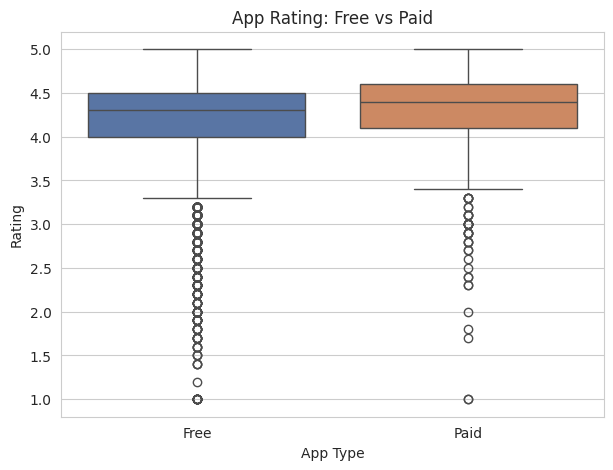

In [ ]:
# Chart - 8 visualization code

plt.figure(figsize=(7, 5))

# Box plot of Rating for Free and Paid apps (missing ratings are ignored automatically)
sns.boxplot(data=df, x="Type", y="Rating", palette=["#4C72B0", "#DD8452"])

plt.title("App Rating: Free vs Paid")
plt.xlabel("App Type")
plt.ylabel("Rating")
plt.show()

##### 1. Why did you pick the specific chart?

A box plot compares a numerical variable across groups, and it shows the median and the spread together, which a bar of averages would hide.

##### 2. What is/are the insight(s) found from the chart?

Paid apps are rated slightly higher: median 4.4 vs 4.3 for free apps, and mean 4.26 vs 4.17. About 81% of paid apps are rated 4.0 or above, against 76% of free apps. The two boxes overlap heavily, so the gap is small. Both groups have a tail of low outliers.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: paid apps keep a slightly higher rating, so a paid model does not hurt user satisfaction, and developers can charge for a polished app without expecting worse ratings.
Negative: the difference is only about 0.1 points, so a paid model alone does not guarantee better quality, and users who pay may simply be more careful about what they buy. Also, only 602 paid apps have ratings (compared with 7,594 free), so the paid result rests on a small sample.

#### Chart - 9 - Rating Spread in the Top 10 Categories

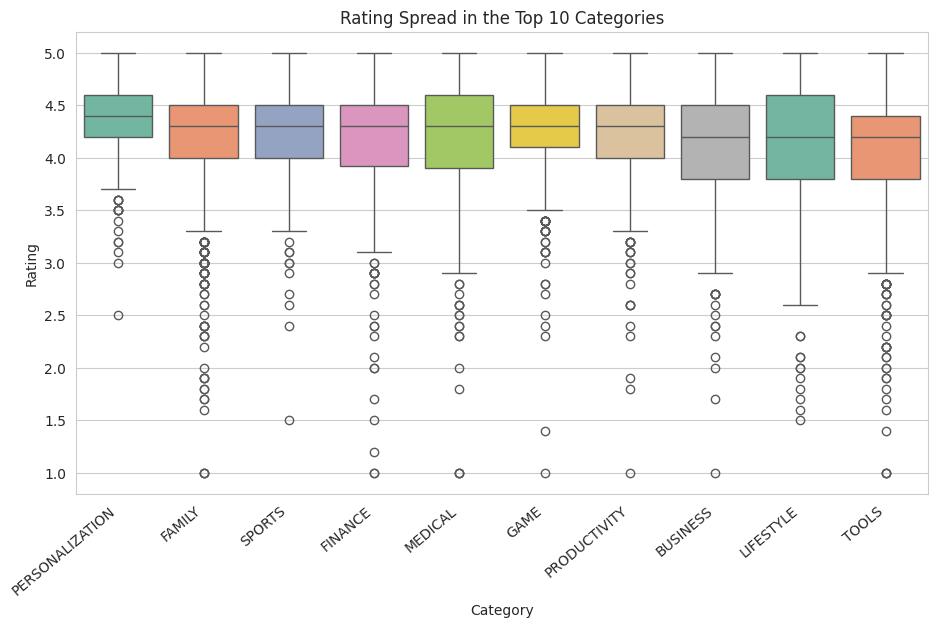

In [ ]:
# Chart - 9 visualization code

# Keep only the 10 categories with the most apps, so the chart stays readable
top10 = df["Category"].value_counts().head(10).index
top_df = df[df["Category"].isin(top10)]

# Order categories by median rating (highest first)
order = top_df.groupby("Category")["Rating"].median().sort_values(ascending=False).index

plt.figure(figsize=(11, 6))
sns.boxplot(data=top_df, x="Category", y="Rating", order=order, palette="Set2")

plt.title("Rating Spread in the Top 10 Categories")
plt.xlabel("Category")
plt.ylabel("Rating")
plt.xticks(rotation=40, ha="right")
plt.show()

##### 1. Why did you pick the specific chart?

A box plot compares both the typical rating and the spread across several categories. A bar of averages would hide the spread, and spread tells us how consistent quality is in a category.

##### 2. What is/are the insight(s) found from the chart?

Medians are close, between 4.2 and 4.4. Personalization is the highest (median 4.4) and also the most consistent (spread of 0.36), and Game has a tight spread too (0.39). Tools, Lifestyle and Business have the lowest medians (4.2) and the widest spreads (about 0.62 to 0.70), and Medical and Finance also vary a lot (0.66 to 0.69). Across all categories, Books & Reference and Health & Fitness reach a median of 4.5, and Dating is the lowest at 4.1.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: the wide spread in Tools, Business and Lifestyle means many apps there are poorly rated, so a well-built app can stand out easily. Strong, consistent categories like Personalization and Game show what a good rating looks like.
Negative: in Personalization and Game, most apps already score 4.2 or more, so a new app needs very high quality just to match the average. In the wide-spread categories, a weak launch can easily land in the low tail and hurt installs.

#### Chart - 10 - Installs by Type (Free vs Paid)

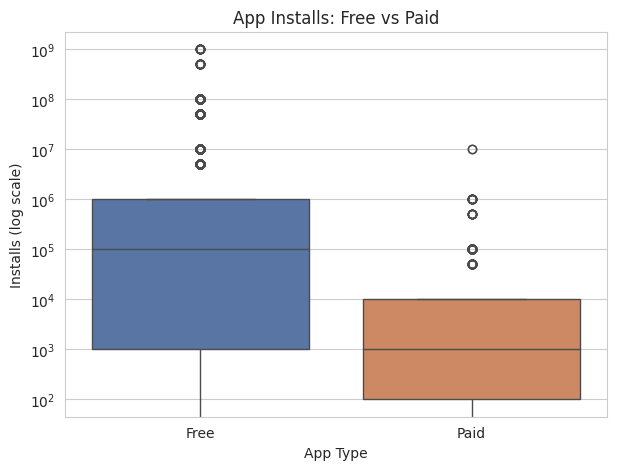

In [ ]:
# Chart - 10 visualization code

plt.figure(figsize=(7, 5))

# Box plot of Installs for Free and Paid apps
sns.boxplot(data=df, x="Type", y="Installs", palette=["#4C72B0", "#DD8452"])

# Installs range from 0 to 1 billion, so a log scale makes the boxes visible
plt.yscale("log")

plt.title("App Installs: Free vs Paid")
plt.xlabel("App Type")
plt.ylabel("Installs (log scale)")
plt.show()

##### 1. Why did you pick the specific chart?

A box plot compares the median and spread of installs between two groups, and the log scale lets us see both groups on one chart even though their sizes differ by a factor of 100.

##### 2. What is/are the insight(s) found from the chart?

Free apps have a median of 100,000 installs, but paid apps have a median of only 1,000, which is 100 times lower. About 38% of free apps cross 1 million installs, compared with only 3% of paid apps, and 55% of paid apps stay at 1,000 installs or fewer.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: free apps get far more reach, so a free app with ads or in-app purchases is the better route to a large user base. A strong user base can then be turned into revenue.
Negative: a paid app typically reaches only about 1,000 installs, so the income from direct sales is small unless the app fills a clear niche. Combined with Chart 8 (paid apps are rated slightly higher), paid apps look like a small, loyal audience, and not a route to mass reach.

#### Chart - 11 - Median Installs by Content Rating

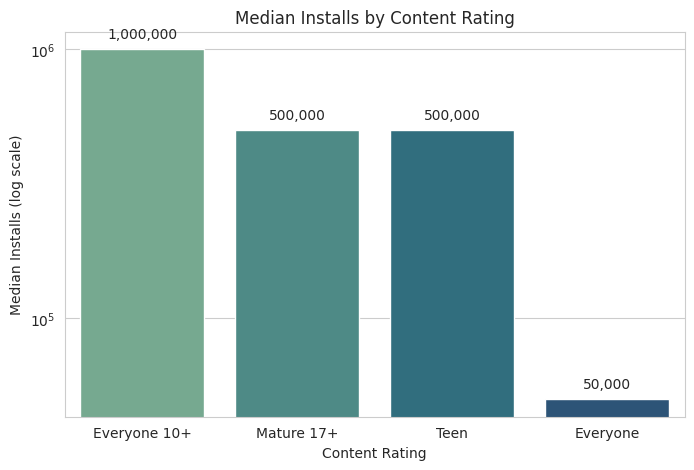

In [ ]:
# Chart - 11 visualization code

# Keep content ratings with at least 100 apps (Adults only and Unrated have 3 and 2)
cr_counts = df["Content Rating"].value_counts()
cr_df = df[df["Content Rating"].isin(cr_counts[cr_counts >= 100].index)]

cr_median = cr_df.groupby("Content Rating")["Installs"].median().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
ax = sns.barplot(x=cr_median.index, y=cr_median.values, palette="crest")
plt.yscale("log")
for i, v in enumerate(cr_median.values):
    ax.text(i, v * 1.1, f"{int(v):,}", ha="center")    # label each bar with its value
plt.title("Median Installs by Content Rating")
plt.xlabel("Content Rating")
plt.ylabel("Median Installs (log scale)")
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart of medians compares reach across content-rating groups, and the log scale keeps the small bar visible.

##### 2. What is/are the insight(s) found from the chart?

Everyone 10+ has the highest median (1,000,000), followed by Teen and Mature 17+ (500,000 each). "Everyone" has the lowest median (50,000) even though it holds 82% of all apps.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: Teen and Everyone 10+ apps reach 10 to 20 times more installs at the median, so targeting these groups looks rewarding. Negative: "Everyone" is the most crowded group with the weakest typical result. This could be partly due to categories (games are common in Teen), so it is an association and not proof.

#### Chart - 12 - Average Sentiment by Category

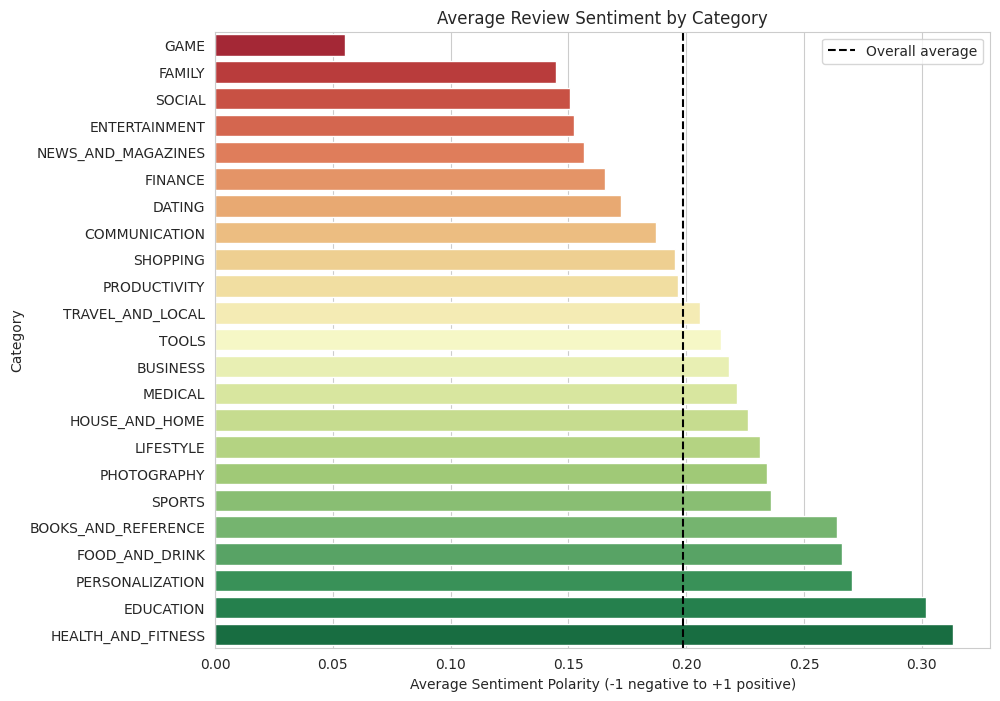

In [ ]:
# Chart - 12 visualization code

sent_df = merged_df.dropna(subset=["avg_polarity"])    # apps that have review data

# Average polarity per category; keep categories with at least 15 apps, so averages are reliable
cat_sent = sent_df.groupby("Category").agg(
    app_count=("App", "count"), avg_polarity=("avg_polarity", "mean")).reset_index()
cat_sent = cat_sent[cat_sent["app_count"] >= 15].sort_values("avg_polarity")

plt.figure(figsize=(10, 8))
sns.barplot(data=cat_sent, x="avg_polarity", y="Category", palette="RdYlGn")
plt.axvline(sent_df["avg_polarity"].mean(), color="black", linestyle="--", label="Overall average")
plt.title("Average Review Sentiment by Category")
plt.xlabel("Average Sentiment Polarity (-1 negative to +1 positive)")
plt.ylabel("Category")
plt.legend()
plt.show()

##### 1. Why did you pick the specific chart?



A sorted bar chart compares a numerical score across many categories and ranks them.


##### 2. What is/are the insight(s) found from the chart?

Game has the lowest sentiment (0.06) by a wide margin, far below the overall average of 0.20, and on average about 39% of a Game app's reviews are negative. Health & Fitness (0.31), Education (0.30) and Personalization (0.27) are the most positive.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: Health & Fitness and Education users are the happiest, so these categories offer a satisfied audience. Negative: Game is the most popular category (median 1M installs) but its users are the most critical, so game developers must invest in bug fixes and fair monetisation. Only 816 apps are covered, so treat this as a strong hint, not proof.

#### Chart - 13 - Competition vs Demand: Apps per Category vs Median Installs

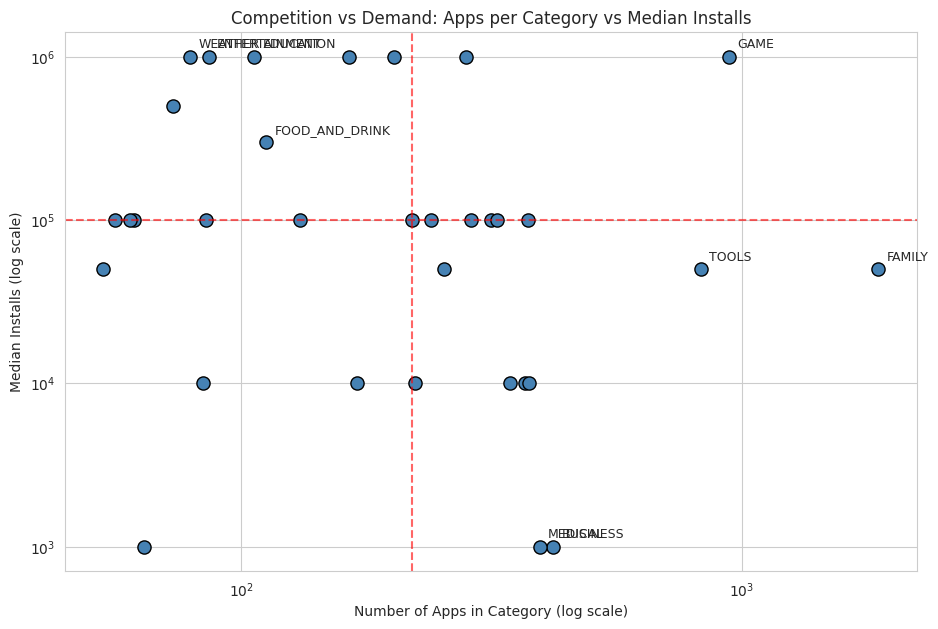

In [ ]:
# Chart - 13 visualization code

# For each category: number of apps and median installs
cat_summary = df.groupby("Category").agg(
    app_count=("App", "count"),
    median_installs=("Installs", "median")
).reset_index()

plt.figure(figsize=(11, 7))
plt.scatter(cat_summary["app_count"], cat_summary["median_installs"],
            s=90, color="steelblue", edgecolor="black")

# Dashed lines at the middle values split the chart into four zones
plt.axvline(cat_summary["app_count"].median(), color="red", linestyle="--", alpha=0.6)
plt.axhline(cat_summary["median_installs"].median(), color="red", linestyle="--", alpha=0.6)

# Label only the categories we discuss, so the chart stays readable
to_label = ["FAMILY", "GAME", "TOOLS", "BUSINESS", "MEDICAL",
            "EDUCATION", "ENTERTAINMENT", "WEATHER", "FOOD_AND_DRINK"]
for _, row in cat_summary[cat_summary["Category"].isin(to_label)].iterrows():
    plt.annotate(row["Category"], (row["app_count"], row["median_installs"]),
                 xytext=(6, 6), textcoords="offset points", fontsize=9)

# Log scale on both axes, because the values range from hundreds to millions
plt.xscale("log")
plt.yscale("log")
plt.title("Competition vs Demand: Apps per Category vs Median Installs")
plt.xlabel("Number of Apps in Category (log scale)")
plt.ylabel("Median Installs (log scale)")
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot compares two numerical measures for each category at once. Here it puts competition (app count) against demand (median installs), so crowded and underserved categories are visible in one view.

##### 2. What is/are the insight(s) found from the chart?

Seven categories reach a median of 1,000,000 installs. Education (106 apps), Entertainment (87) and Weather (79) do it with few apps, while Game (945 apps) does it with many. At the other end, Family has 1,876 apps with a median of only 50,000 installs, and Business (420 apps) and Medical (395 apps) have a median of just 1,000 installs. The overall link is weak and negative (Spearman about -0.26), so more apps in a category tends to go with slightly lower median installs.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: Education, Entertainment, Weather and Food & Drink combine a high median (300K to 1M installs) with relatively few apps (under 115 each), so a new developer faces less competition for the same audience. Game is proven demand, since even its median app gets 1M installs.
Negative: Family, Tools, Business and Medical are crowded with a low typical result, so a typical new app there will struggle to be seen. Caution: a low median in Medical or Business may come from a small niche audience rather than only from competition, so a developer should not treat these as "empty markets".

#### Chart - 14 - Reviews vs Installs

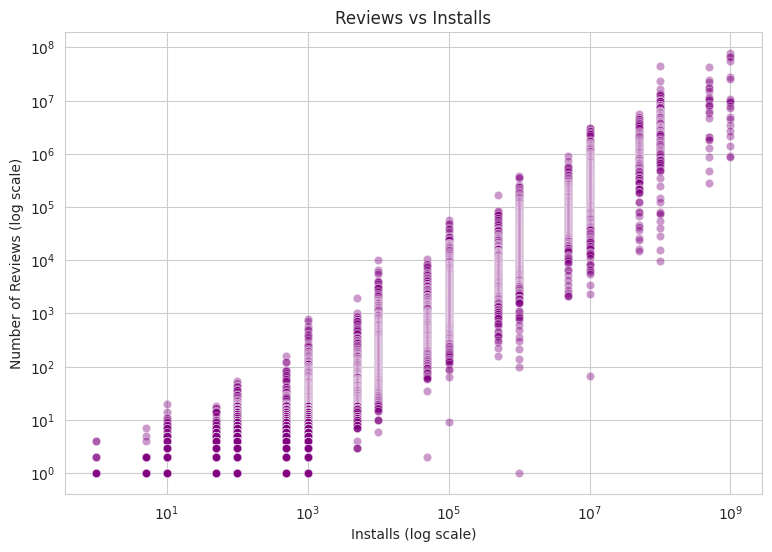

In [ ]:
# Chart - 14 visualization code

# Log scale cannot show zero, so keep apps with at least 1 review and 1 install
plot_df = df[(df["Reviews"] > 0) & (df["Installs"] > 0)]

plt.figure(figsize=(9, 6))

# Each dot is one app; alpha makes overlapping dots visible
sns.scatterplot(data=plot_df, x="Installs", y="Reviews", alpha=0.4, color="purple")

# Both columns range from tiny to millions, so use log scales
plt.xscale("log")
plt.yscale("log")

plt.title("Reviews vs Installs")
plt.xlabel("Installs (log scale)")
plt.ylabel("Number of Reviews (log scale)")
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot is the standard way to see the relationship between two numerical variables, such as its direction, strength and any unusual points.

##### 2. What is/are the insight(s) found from the chart?

There is a very strong upward relationship (rank correlation about 0.97). The median app with 1 million installs has about 22,000 reviews, and the median app with 100,000 installs has about 1,700. The typical app gets about 2 reviews for every 100 installs (median ratio about 1.9%), so reviews follow reach closely.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: since reviews grow with installs, a developer can use review count as an easy health check. An app that gets far fewer than about 2 reviews per 100 installs has low engagement, and prompting happy users to leave a review would help it catch up.
Negative: this shows association, not cause. More reviews help visibility, but the chart cannot prove they drive installs. It also means small apps have very little feedback, which makes it hard for a new developer to learn what users want.

#### Chart - 15 - App Size vs Rating

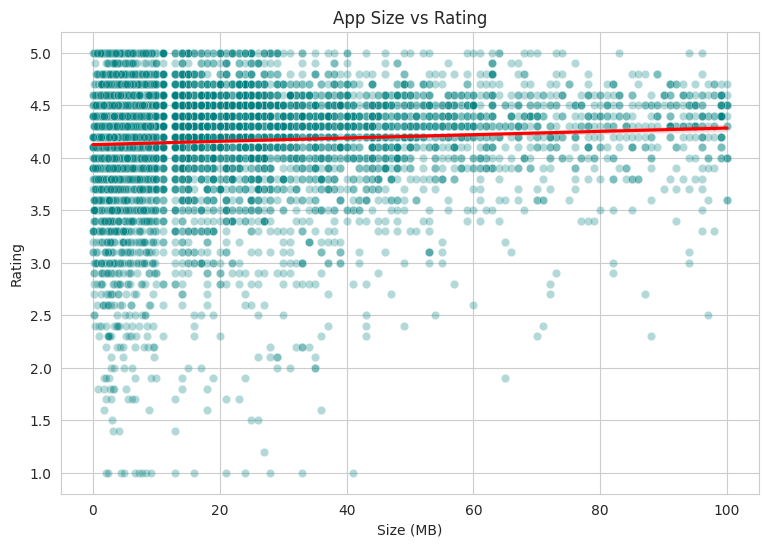

In [ ]:
# Chart - 15 visualization code

# Keep apps that have a rating and a real size
# (remove the size filled with the median during cleaning, as in Chart 6)
plot_df = df[(df["Size"] != df["Size"].median())].dropna(subset=["Rating"])

plt.figure(figsize=(9, 6))

# Scatter of size vs rating; alpha makes overlapping dots visible
sns.scatterplot(data=plot_df, x="Size", y="Rating", alpha=0.3, color="teal")

# Trend line to show the overall direction
sns.regplot(data=plot_df, x="Size", y="Rating", scatter=False, color="red")

plt.title("App Size vs Rating")
plt.xlabel("Size (MB)")
plt.ylabel("Rating")
plt.show()

##### 1. Why did you pick the specific chart?



A scatter plot with a trend line shows whether two numerical variables move together, and whether any pattern or outliers exist.

##### 2. What is/are the insight(s) found from the chart?

There is almost no relationship between size and rating (correlation about 0.06). The dots form a wide band with no clear direction. Median rating is nearly the same across size groups: 4.2 for apps under 5 MB and 4.3 for the rest, including apps of 50-100 MB. Most low ratings appear at all sizes.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: size does not drive rating, so developers do not need to shrink an app at the cost of features just to improve ratings. Rich, larger apps are rated as well as small ones.
Negative: this chart cannot say whether size affects installs (large downloads may still put off users with limited storage or slow internet), so developers should not assume size is harmless for growth. Also, very small apps (under 5 MB) have slightly lower ratings (median 4.2), possibly because they are simple utilities, so being small is not an advantage by itself.

#### Chart - 16 - Rating vs Review Sentiment

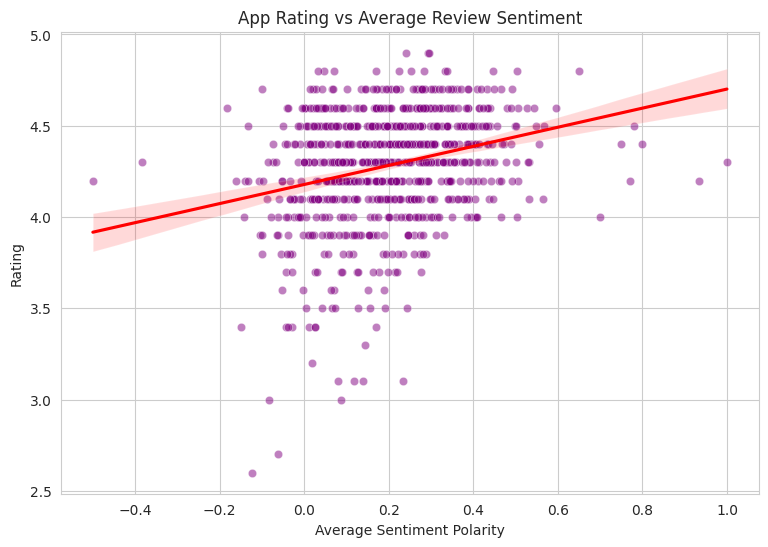

In [ ]:
# Chart - 16 visualization code

plot_df = sent_df.dropna(subset=["Rating"])

plt.figure(figsize=(9, 6))
sns.scatterplot(data=plot_df, x="avg_polarity", y="Rating", alpha=0.5, color="purple")
sns.regplot(data=plot_df, x="avg_polarity", y="Rating", scatter=False, color="red")  # trend line
plt.title("App Rating vs Average Review Sentiment")
plt.xlabel("Average Sentiment Polarity")
plt.ylabel("Rating")
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot with a trend line shows whether two numerical measures of satisfaction agree.

##### 2. What is/are the insight(s) found from the chart?

The link is positive but weak (Spearman 0.25, 816 apps). Apps with happier reviews tend to have higher ratings, but many apps with a rating above 4 have only average review sentiment. Sentiment is also slightly negative with installs (-0.25), so more popular apps tend to get less positive reviews.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: review text carries information that the star rating hides, so reading the reviews gives developers an early warning. Negative: a good rating can hide unhappy users, so relying only on stars may miss problems. Of the apps with sentiment, only 9 are paid, so this result mostly describes free apps.

#### Chart - 17 - Price vs Rating (Paid Apps)

Text(0, 0.5, 'Rating')

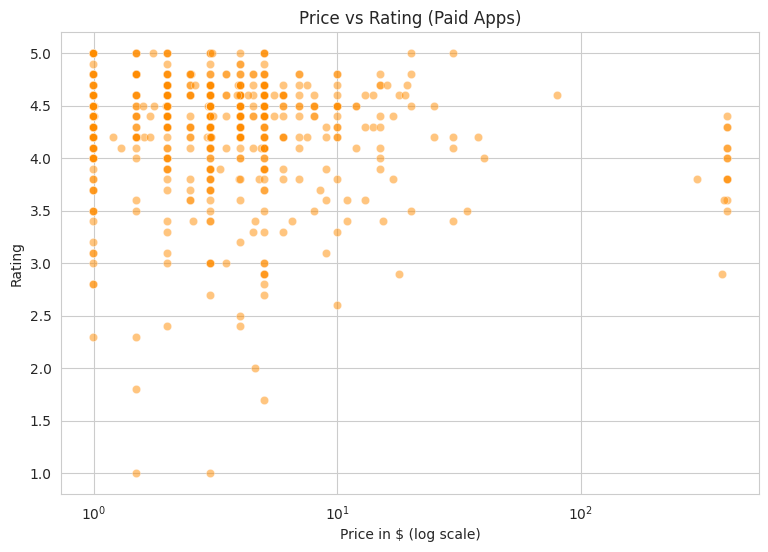

In [ ]:
# Chart - 17 visualization code

paid_df = df[df["Type"] == "Paid"].dropna(subset=["Rating"])    # 602 paid apps with a rating

plt.figure(figsize=(9, 6))
sns.scatterplot(data=paid_df, x="Price", y="Rating", alpha=0.5, color="darkorange")
plt.xscale("log")      # prices run from $0.99 to $400, so use a log scale
plt.title("Price vs Rating (Paid Apps)")
plt.xlabel("Price in $ (log scale)")
plt.ylabel("Rating")

##### 1. Why did you pick the specific chart?

A scatter plot shows whether a higher price goes with higher or lower satisfaction among paid apps.

##### 2. What is/are the insight(s) found from the chart?

Price and rating are only slightly related (Spearman -0.10).
Median rating is 4.4 for every price band up to $10
and drops to 4.2 above $10.

The median paid price is $2.99, and 75% of paid apps cost under $5.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: pricing up to $10 does not hurt ratings, so developers can price by value without worrying about rating. Negative: apps above $10 are rated slightly lower (only 55 apps, so a small sample), and extreme prices like $400 are outliers that should not guide pricing.

#### Chart - 18 - Free vs Paid Share in the Top 10 Categories

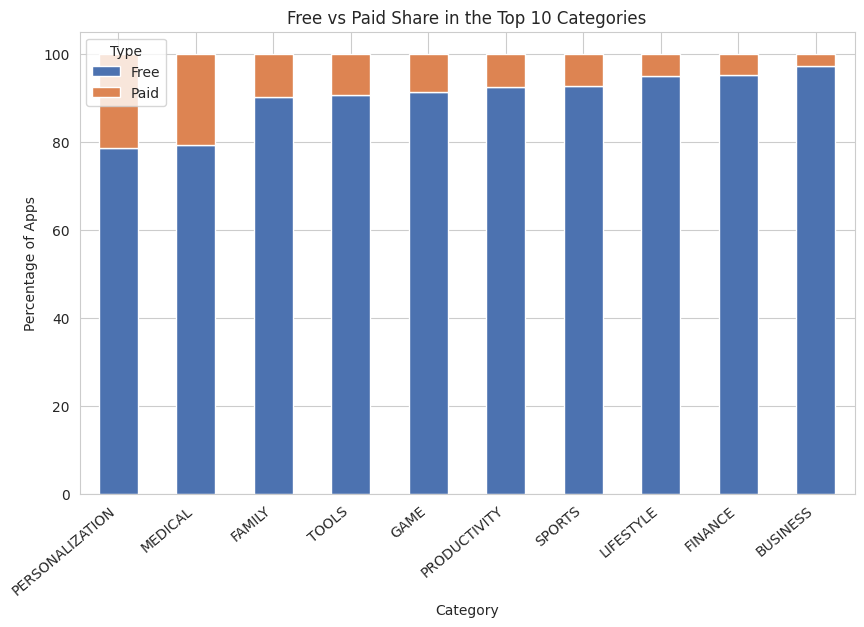

In [ ]:
# Chart - 18 visualization code

top10 = df["Category"].value_counts().head(10).index
top_df = df[df["Category"].isin(top10)]

# Percentage of Free and Paid apps within each category
type_pct = pd.crosstab(top_df["Category"], top_df["Type"], normalize="index") * 100
type_pct = type_pct.sort_values("Paid", ascending=False)

type_pct.plot(kind="bar", stacked=True, figsize=(10, 6), color=["#4C72B0", "#DD8452"])
plt.title("Free vs Paid Share in the Top 10 Categories")
plt.xlabel("Category")
plt.ylabel("Percentage of Apps")
plt.xticks(rotation=40, ha="right")
plt.legend(title="Type")
plt.show()

##### 1. Why did you pick the specific chart?

A 100% stacked bar compares a categorical split (Free/Paid) across categories fairly, even when categories differ in size.

##### 2. What is/are the insight(s) found from the chart?

Personalization (21.5%) and Medical (20.8%) have the highest share of paid apps. Business (2.9%), Finance (4.9%) and Lifestyle (5.1%) have the lowest. Other categories sit near 8-10%.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Positive: users in Personalization and Medical already accept paying, so a paid model is more normal there. Negative: Medical has a low median of only 1,000 installs, so a high paid share does not mean easy revenue, and in Business and Finance almost everything is free, so charging up front is risky.

### Multivariate Analysis (Charts 19 and 20)
Several variables together, to check whether the patterns hold.

#### Chart - 19 - Correlation Heatmap

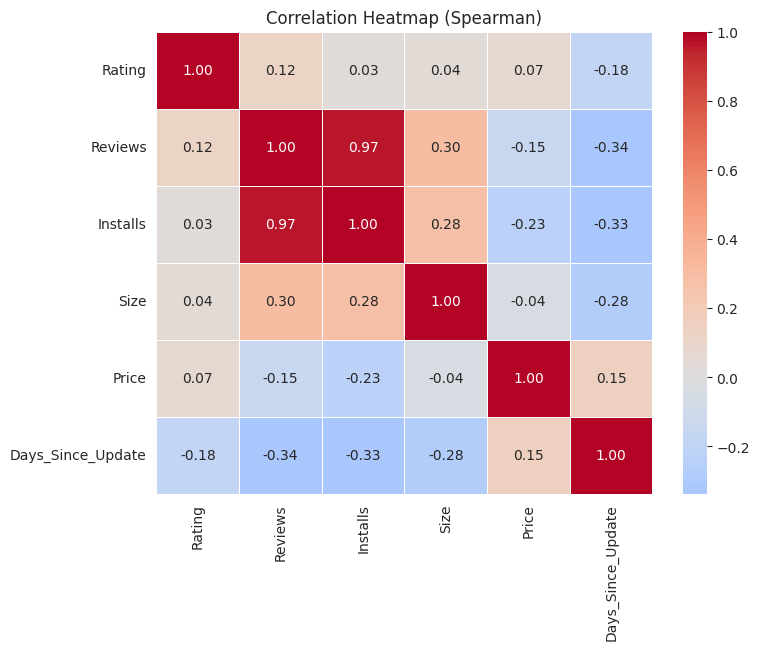

In [ ]:
# Chart - 19 visualization code

# New column: days between each app's last update and the latest update date in the data
df["Days_Since_Update"] = (df["Last Updated"].max() - df["Last Updated"]).dt.days

# Numeric columns to compare
num_cols = ["Rating", "Reviews", "Installs", "Size", "Price", "Days_Since_Update"]

# Spearman correlation: better than Pearson here because Reviews and Installs are very skewed
corr = df[num_cols].corr(method="spearman")

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Heatmap (Spearman)")
plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap compares every pair of numeric variables at once, so we see which factors move together without making many separate charts. It is the standard multivariate chart.

##### 2. What is/are the insight(s) found from the chart?

Reviews and Installs are almost perfectly linked (0.97). More reach means more reviews.
Rating is only weakly related to everything else, with values between -0.18 and 0.12. Installs (0.03), Size (0.04) and Price (0.07) hardly move with Rating, so a high rating does not bring high installs.
Update recency matters: Days_Since_Update is negatively related to Installs (-0.33) and Reviews (-0.34), so the older the last update, the lower the installs. It is also negatively related to Rating (-0.18).
Price has a negative link with Installs (-0.23), so costlier apps get fewer installs.
Size has a small positive link with Installs (0.28), so larger apps tend to be more popular, probably because they are richer apps like games.
Correlation shows association only, not cause.

#### Chart - 20 - Pair Plot

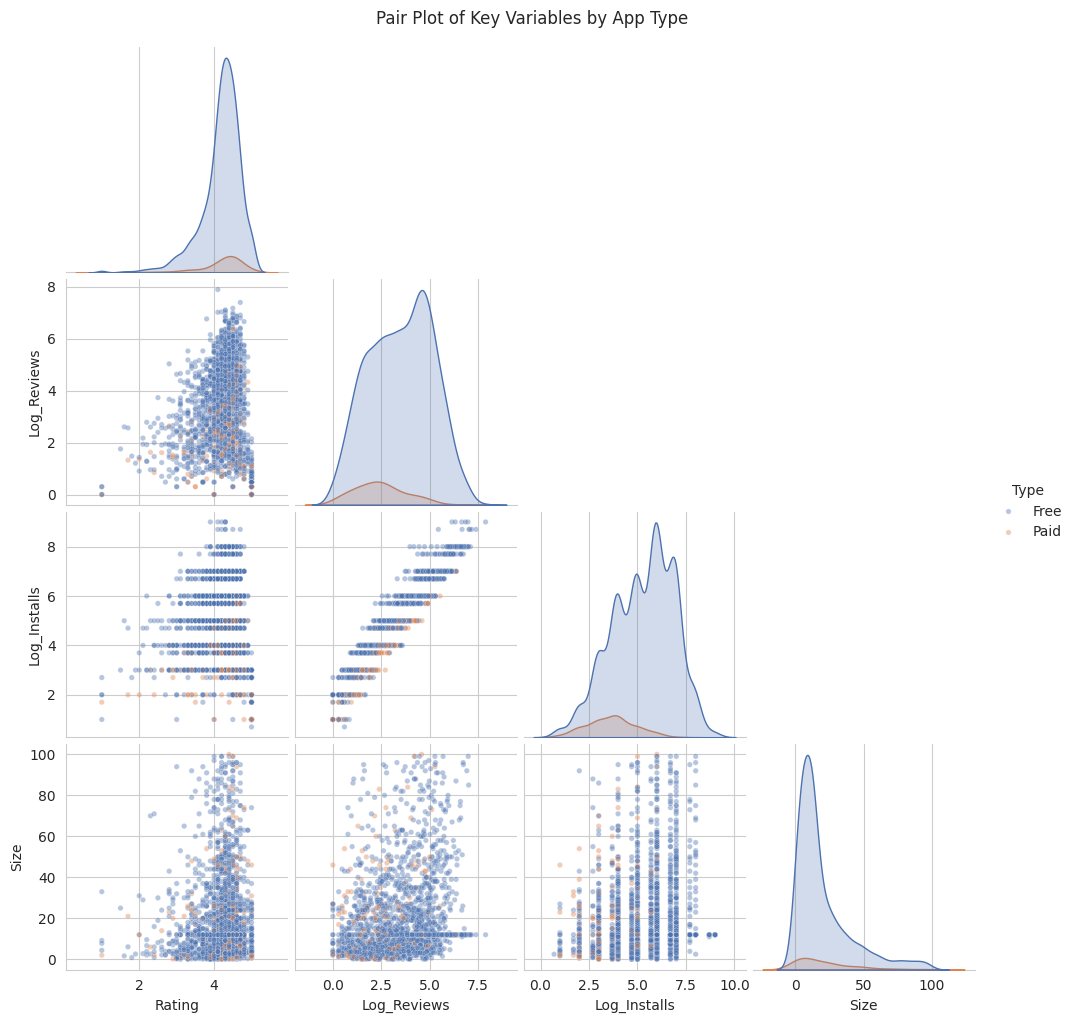

In [ ]:
# Chart - 20 visualization code

# Keep apps with a rating and positive reviews/installs (needed for the log transform)
pair_df = df[(df["Reviews"] > 0) & (df["Installs"] > 0)].dropna(subset=["Rating"]).copy()

# Reviews and Installs are very skewed, so use their log10 values
pair_df["Log_Reviews"] = np.log10(pair_df["Reviews"])
pair_df["Log_Installs"] = np.log10(pair_df["Installs"])

# Plot a random sample of 2,000 apps: faster, and the pattern stays the same
sample_df = pair_df.sample(2000, random_state=42)

# Pair plot coloured by Type; corner=True removes the repeated upper half
sns.pairplot(sample_df[["Rating", "Log_Reviews", "Log_Installs", "Size", "Type"]],
             hue="Type", palette={"Free": "#4C72B0", "Paid": "#DD8452"},
             plot_kws={"alpha": 0.4, "s": 15}, corner=True)
plt.suptitle("Pair Plot of Key Variables by App Type", y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows the relationships between several numeric variables in one figure, and the color split adds a third variable (Type). It is a good multivariate check after the heatmap, because it shows the shape of each relationship, which a single correlation number hides.

##### 2. What is/are the insight(s) found from the chart?

Reviews and Installs form a clear straight line on the log scale, which confirms the strong link from the heatmap.
Paid apps sit in the lower-left zone. Their typical installs are around 5,000 (log value 3.7) against about 500,000 for free apps (5.7), and their typical reviews are about 200 against about 3,900.
Rating is concentrated between 4 and 5 for both types, and it forms a flat band against every other variable, so rating does not change with size, reviews or installs in any strong way.
Size shows no clear pattern with any variable. The apparent vertical line at 12 MB comes from the median filled during cleaning.

### Statistical Analysis

In [ ]:
from scipy import stats

# Test 1: do free and paid apps have different ratings?
# Mann-Whitney U is used because ratings are skewed, not normally distributed
free_rating = df.loc[df["Type"] == "Free", "Rating"].dropna()
paid_rating = df.loc[df["Type"] == "Paid", "Rating"].dropna()
u_stat, p_value = stats.mannwhitneyu(free_rating, paid_rating, alternative="two-sided")
print("Free vs Paid rating, p-value:", p_value)

# Test 2: are Reviews and Installs related?
rho, p_corr = stats.spearmanr(df["Reviews"], df["Installs"])
print("Reviews vs Installs, Spearman correlation:", round(rho, 3), "| p-value:", p_corr)

Free vs Paid rating, p-value: 8.108375019564798e-11
Reviews vs Installs, Spearman correlation: 0.968 | p-value: 0.0


## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?
Explain Briefly.

### Solution to Business Objective

**Objective:** help app developers build apps that get more installs, better ratings and more engagement.

**Suggestions to the client**

1. **Choose the category carefully.** Education, Entertainment, Weather and Food & Drink reach a median of 300K to 1M installs with relatively few apps, so competition is lower. Family, Tools, Business and Medical are crowded with low median installs (50K or less), so enter them only with a clearly different idea. Game has strong demand (1M median installs), but its users are the most critical.
2. **Prefer a free model.** Free apps have a median of 100,000 installs against 1,000 for paid apps. Earn through ads or in-app purchases, and keep a paid model for a clear niche such as Personalization, where about 1 in 5 apps is already paid. If you do charge, keep the price under $10, because ratings stay at 4.4 up to that level.
3. **Keep the app updated.** The longer since the last update, the fewer the installs (correlation -0.33). Plan regular updates after launch.
4. **Target a rating of 4.3 or more.** The median rating is 4.3 and 77% of apps are rated 4.0 or above, so anything below 4.0 puts the app behind most competitors. Test and fix bugs before launch.
5. **Do not rely on rating alone.** Rating is only weakly linked to installs and to review sentiment, so combine quality with the right category, marketing and a target audience (Teen and Everyone 10+ apps have a higher median reach than "Everyone" apps).
6. **Encourage reviews and read the negative ones.** Reviews rise with installs (about 2 per 100 installs), so a low review rate signals low engagement. About 21% of reviews are negative, and Game apps have the most negative sentiment, so fix common complaints early.
7. **Do not worry about app size.** Larger apps are rated as well as small ones, so build the features users need while keeping the download reasonable (the median is about 13 MB).

**Expected result:** a developer who follows these steps enters a less crowded category, reaches more users with a free app, keeps them through updates and quality, and builds engagement by listening to reviews.

*Note: these are patterns found in the data (association, not proof of cause).*

# **Conclusion**

### Conclusion

**1. Data Information (key findings about the data)**
- The Play Store data had 10,841 rows and the Reviews data had 64,295 rows. After cleaning, **9,659 unique apps** and **29,692 usable reviews (865 apps)** remained. After the merge, 816 of those apps matched the Play Store data and have sentiment values.
- Main problems fixed: 1 corrupted row, 1,181 duplicate apps, numeric columns stored as text (Installs, Price, Size, Reviews), "Varies with device" hidden in Size, and many empty review rows.
- Rating is missing for 1,463 apps and was left empty on purpose, so rating analysis uses 8,196 apps.
- Installs and Reviews are heavily skewed (median installs 100,000 vs mean about 7.8 million), so medians, log scales and Spearman correlation were used.

**2. Insights (answers to my key questions)**
1. **Categories:** Family (1,876 apps), Game and Tools are the most crowded. Education, Entertainment, Weather and Food & Drink have a high median (300K to 1M installs) with few apps. Business and Medical have a low median of 1,000 installs despite many apps.
2. **Free vs Paid:** 92% of apps are free. Free apps have a median of 100,000 installs against 1,000 for paid. Paid apps are rated slightly higher (4.4 vs 4.3), which is statistically significant but small. Paid apps are most common in Personalization and Medical (about 21%), and ratings stay at 4.4 for prices up to $10.
3. **Size, update and content rating:** Size has almost no link with rating (correlation about 0.06). Teen and Everyone 10+ apps have a much higher median reach (500K to 1M) than "Everyone" apps (50K).
4. **Sentiment:** 64% of reviews are positive, 21% negative and 15% neutral. Game has the lowest average sentiment (0.06) although it is a very popular category, while Health & Fitness (0.31) and Education (0.30) are the highest. Rating and sentiment are only weakly related (0.25).
5. **Correlations:** Reviews and Installs move together almost perfectly (0.97). Days since last update is negatively related to installs (-0.33). Rating is only weakly related to installs, size and price.

**3. Positive and negative patterns**
- *Positive:* ratings are high overall (median 4.3), recent updates go with higher installs, several categories have strong demand with low competition, and most reviews are positive.
- *Negative:* most apps cluster at 4.0 to 4.6, so rating does not make an app stand out. Paid apps reach very few users. Crowded categories like Family and Tools give new apps a low typical result. Game users are the most critical.

**4. Suggested Actionables**
- Enter a less crowded category with high demand (Education, Entertainment, Weather, Food & Drink).
- Launch free and earn through ads or in-app purchases. If charging, keep the price under $10.
- Update the app regularly after launch.
- Aim for a rating of at least 4.3, and fix common complaints from negative reviews early (especially in Game).
- Encourage reviews to build engagement, and use medians, not averages, when setting targets.

**5. Limitations**
- The findings show association, not cause. For example, popular apps may update more often because they have more resources.
- The data is a 2018 snapshot, so trends may have changed.
- Only 816 apps have matched review data, and only 9 of them are paid, so sentiment findings cover a small part of the market and mostly describe free apps.
- Install counts are ranges (for example "10,000+"), not exact numbers.

### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***